### PACKAGES INSTALL

In [1]:
# !pip3 install matplotlib seaborn statsforecast utilsforecast scikit-learn pandas numpy

### PACKAGES IMPORT

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from statsforecast import StatsForecast
from utilsforecast.plotting import plot_series
from utilsforecast.losses import *
from utilsforecast.evaluation import evaluate
from statsforecast.models import Naive, HistoricAverage, SeasonalNaive, WindowAverage, AutoARIMA
from utilsforecast.feature_engineering import fourier, time_features, pipeline
from functools import partial

C:\Users\shubh\OneDrive\Desktop\Nivēśa\nivesa\python\virtual\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### DATASET ACCESS

In [3]:
data = pd.read_csv('./dataset/transactions_training_data.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83417 entries, 0 to 83416
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           83417 non-null  object 
 1   amount       83417 non-null  float64
 2   description  83417 non-null  object 
 3   category     83417 non-null  object 
 4   type         83417 non-null  object 
 5   date         83417 non-null  object 
 6   status       83417 non-null  object 
 7   isRecurring  83417 non-null  bool   
 8   accountId    83417 non-null  object 
 9   userId       0 non-null      float64
dtypes: bool(1), float64(2), object(7)
memory usage: 5.8+ MB


### DATA PREPROCESSING

In [4]:
data = data.drop(['id', 'accountId', 'userId', 'description'], axis=1) #Just Unique Identifiers
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83417 entries, 0 to 83416
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   amount       83417 non-null  float64
 1   category     83417 non-null  object 
 2   type         83417 non-null  object 
 3   date         83417 non-null  object 
 4   status       83417 non-null  object 
 5   isRecurring  83417 non-null  bool   
dtypes: bool(1), float64(1), object(4)
memory usage: 3.3+ MB


##### CLEANING DATE-TIME FORMATTING

In [5]:
data['date'] = pd.to_datetime(data['date'])
data['date'] = data['date'].dt.date
data['date'].value_counts(dropna=False)

date
2024-09-29    175
2025-09-28    173
2025-06-08    173
2025-04-27    171
2025-06-15    168
             ... 
2025-07-15     77
2025-09-10     75
2026-01-01     73
2024-02-19     65
2026-02-19     40
Name: count, Length: 732, dtype: int64

##### TARGET/MEAN ENCODING CATEGORY INFO

In [6]:
expenses_data = data[data['type'] == "EXPENSE"].copy()
expenses_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 70689 entries, 0 to 83416
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   amount       70689 non-null  float64
 1   category     70689 non-null  object 
 2   type         70689 non-null  object 
 3   date         70689 non-null  object 
 4   status       70689 non-null  object 
 5   isRecurring  70689 non-null  bool   
dtypes: bool(1), float64(1), object(4)
memory usage: 3.3+ MB


In [7]:
category_means = expenses_data.groupby('category')['amount'].mean()
category_means.head(20)

category
EDUCATION        15487.002759
ENTERTAINMENT     1594.621081
FOOD               799.805507
HEALTHCARE        7784.800230
HOUSING          14889.662880
OTHER             2539.103828
SHOPPING          5262.577117
TRANSPORT          423.525137
Name: amount, dtype: float64

In [8]:
expenses_data['category_encoded'] = expenses_data['category'].map(category_means)
expenses_data.value_counts(dropna=False)

amount    category       type     date        status     isRecurring  category_encoded
50.07     TRANSPORT      EXPENSE  2025-11-02  COMPLETED  False        423.525137          1
6503.68   HOUSING        EXPENSE  2025-01-13  COMPLETED  False        14889.662880        1
6505.41   SHOPPING       EXPENSE  2025-12-31  COMPLETED  False        5262.577117         1
6505.22   HOUSING        EXPENSE  2025-06-04  COMPLETED  False        14889.662880        1
6504.31   EDUCATION      EXPENSE  2025-11-22  COMPLETED  False        15487.002759        1
                                                                                         ..
1301.33   FOOD           EXPENSE  2025-11-29  COMPLETED  False        799.805507          1
1301.42   ENTERTAINMENT  EXPENSE  2025-10-11  COMPLETED  False        1594.621081         1
1301.45   FOOD           EXPENSE  2024-06-19  COMPLETED  False        799.805507          1
1301.60   FOOD           EXPENSE  2024-03-22  PENDING    False        799.805507     

##### AGGREGATING ACCORDING TO DAILY TRANSACTIONS

In [9]:
daily_transactions = expenses_data.groupby('date').agg({
    'amount': 'sum', # Total Amount Of Money Moved That Day
    'category_encoded': 'mean', # most frequent category of that day
    'type': 'count' # how many expense transactions that day
}).reset_index() # Back to dataframe

daily_transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              732 non-null    object 
 1   amount            732 non-null    float64
 2   category_encoded  732 non-null    float64
 3   type              732 non-null    int64  
dtypes: float64(2), int64(1), object(1)
memory usage: 23.0+ KB


In [10]:
daily_transactions = daily_transactions.rename(columns={
    'amount': 'y', # Will be the target
    'type': 'transactions_count', # Exogenous Features
    'date': 'ds', # Will be the date-indicator for time series
    'category_encoded': 'category_expenditure_mean' # The weighted average of the entire spending of a day
})

daily_transactions.head(10)

,ds,y,category_expenditure_mean,transactions_count
0,2024-02-19,375112.02,5940.618581,56
1,2024-02-20,627249.18,5998.982858,95
2,2024-02-21,461928.59,5376.538484,84
3,2024-02-22,593327.86,6153.814004,102
4,2024-02-23,413934.57,5751.630291,79
5,2024-02-24,705662.07,6696.008945,107
6,2024-02-25,774866.88,6301.862681,122
7,2024-02-26,514567.85,5277.847342,101
8,2024-02-27,529695.09,5607.571741,88
9,2024-02-28,523465.44,6553.515864,81


##### CHECKING OUTLIERS

<Axes: xlabel='y', ylabel='Count'>

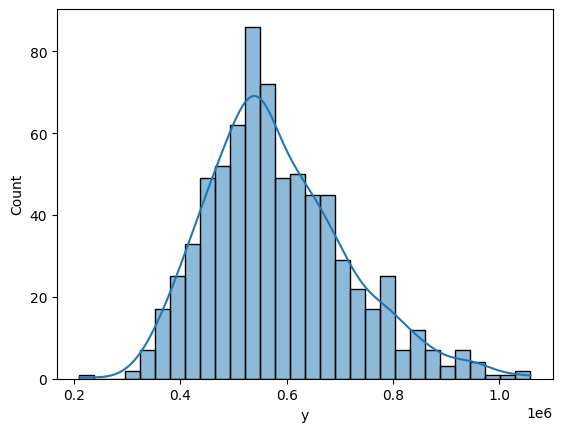

In [11]:
sns.histplot(daily_transactions['y'], kde=True, bins=30)

<Axes: xlabel='y', ylabel='Count'>

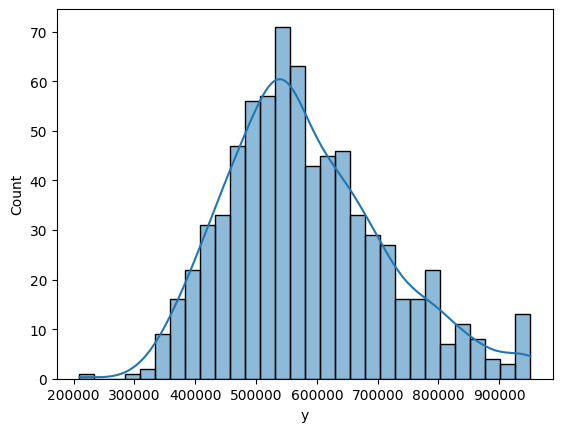

In [12]:
#Winsorization
upper_limit = daily_transactions['y'].quantile(0.99)
daily_transactions['y'] = daily_transactions['y'].clip(upper=upper_limit)
sns.histplot(daily_transactions['y'], kde=True, bins=30)

##### PLOTTING THE TIME-SERIES

In [13]:
daily_transactions['unique_id'] = 'expenses'
daily_transactions['ds'] = pd.to_datetime(daily_transactions['ds'])
daily_transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   ds                         732 non-null    datetime64[ns]
 1   y                          732 non-null    float64       
 2   category_expenditure_mean  732 non-null    float64       
 3   transactions_count         732 non-null    int64         
 4   unique_id                  732 non-null    object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(1)
memory usage: 28.7+ KB


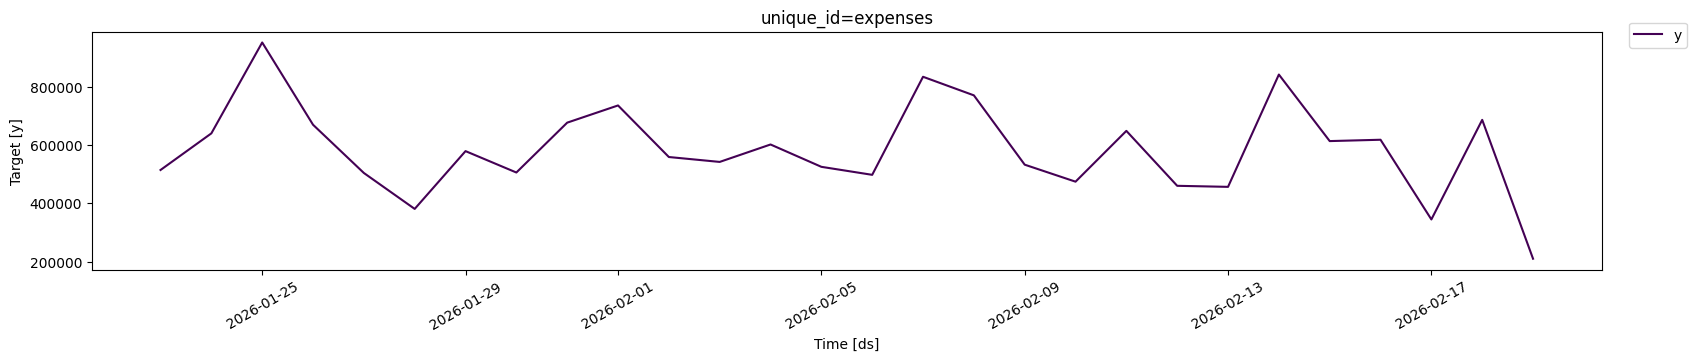

In [14]:
plot_series(
    df=daily_transactions,
    max_insample_length=28,
    palette='viridis'
)

### BASELINE STATS MODELS

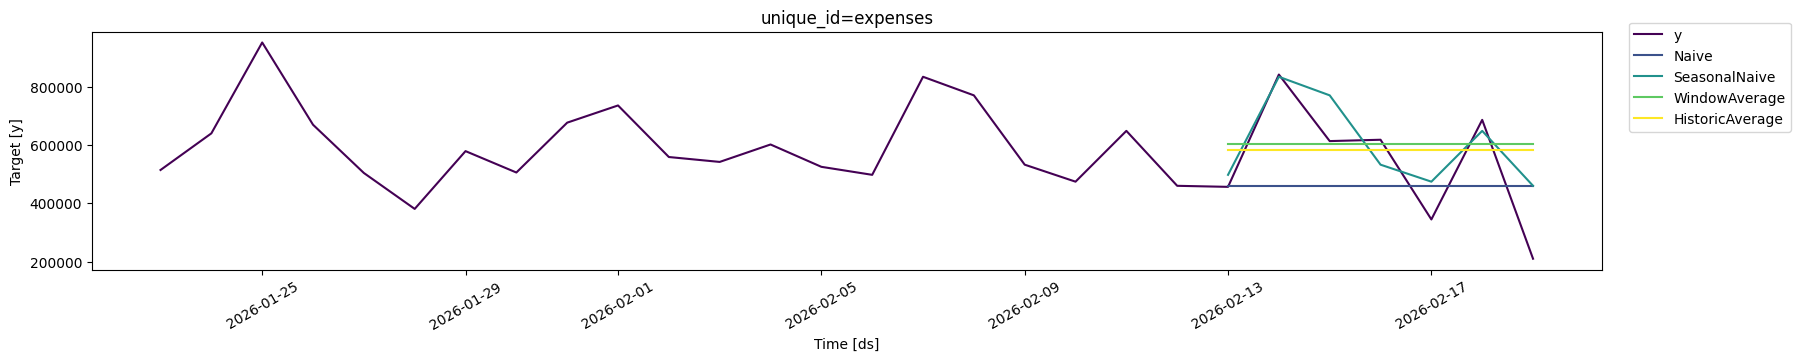

In [15]:
# DATASETS
daily_transactions = daily_transactions.sort_values('ds').reset_index(drop=True)
test_data = daily_transactions.tail(7) # Keeping Last 7 Days Data
train_data = daily_transactions.drop(test_data.index) # Training Dataset
horizon = 7 # Predicting For Next Week
# BASELINE MODELS
models = [
    Naive(),
    SeasonalNaive(season_length=7), # Assuming Weekly Seasonality
    WindowAverage(window_size=7), # Using Window Size of 7, recent weeks average
    HistoricAverage()
]
# TRAINING THE MODEL
baseline_forecast = StatsForecast(models=models, freq="D")
baseline_forecast.fit(train_data)
baseline_predictions = baseline_forecast.predict(h=horizon)
#PLOTTING THE FORECASTED TIME SERIES
plot_series(df=daily_transactions, forecasts_df=baseline_predictions, max_insample_length=28, palette="viridis")

In [16]:
#EVALUATING THE BASELINE MODELS
evaluation_df = pd.merge(test_data, baseline_predictions, on=["ds", "unique_id"])
baseline_evaluations = evaluate(evaluation_df, metrics=[mae])
baseline_evaluations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   unique_id                  1 non-null      object 
 1   metric                     1 non-null      object 
 2   category_expenditure_mean  1 non-null      float64
 3   transactions_count         1 non-null      float64
 4   Naive                      1 non-null      float64
 5   SeasonalNaive              1 non-null      float64
 6   WindowAverage              1 non-null      float64
 7   HistoricAverage            1 non-null      float64
dtypes: float64(6), object(2)
memory usage: 192.0+ bytes


In [17]:
baseline_evaluations = baseline_evaluations.drop(['unique_id'], axis=1).groupby('metric').mean().reset_index()
baseline_evaluations

,metric,category_expenditure_mean,transactions_count,Naive,SeasonalNaive,WindowAverage,HistoricAverage
0,mae,532530.611209,538109.997143,183959.032857,101200.281429,163621.277755,166368.913601


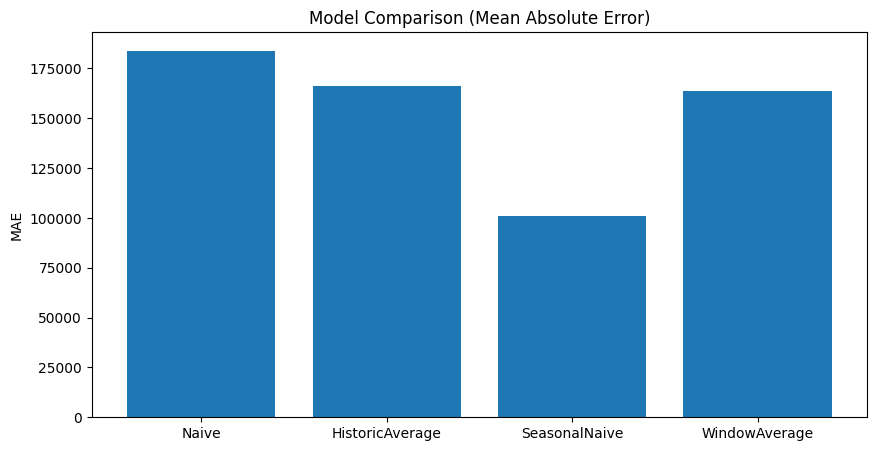

In [18]:
plt.figure(figsize=(10, 5))
evaluation_metric = ["Naive", "HistoricAverage", "SeasonalNaive", "WindowAverage"]
values = baseline_evaluations.loc[0, evaluation_metric]
plt.bar(evaluation_metric, values)
plt.ylabel("MAE")
plt.title("Model Comparison (Mean Absolute Error)")
plt.show()

### STATS MODELS

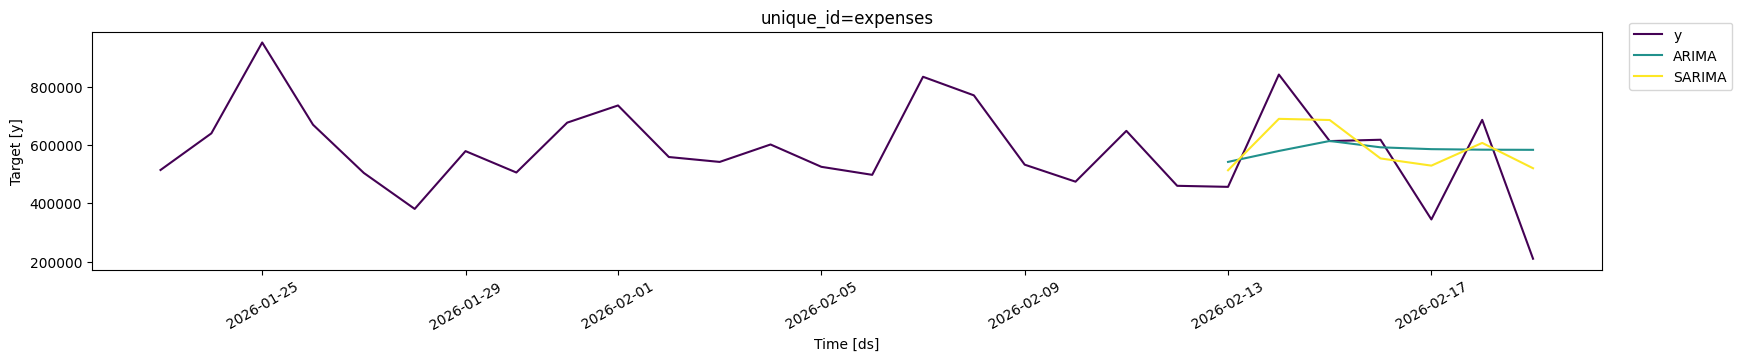

In [19]:
# Stats Models
models = [
    AutoARIMA(seasonal=False, alias="ARIMA"),
    AutoARIMA(season_length=7, alias="SARIMA")
]
#Without Exogenous Features
train_data_no_exog = train_data.drop(["category_expenditure_mean", "transactions_count"], axis=1)
test_data_no_exog = test_data.drop(["category_expenditure_mean", "transactions_count"], axis=1)
# Training The Model
stats_forecast = StatsForecast(models=models, freq="D")
stats_forecast.fit(train_data_no_exog)
stats_predictions = stats_forecast.predict(h=horizon)
# Plotting The Time-Series Graph
plot_series(df=daily_transactions, forecasts_df=stats_predictions, max_insample_length=28, palette="viridis")

In [20]:
# Evaluating The Outcomes
evaluation_df = pd.merge(test_data_no_exog, stats_predictions, on=["unique_id", "ds"])
stats_evaluations = evaluate(evaluation_df, metrics=[mae])
stats_evaluations = stats_evaluations.drop(['unique_id'], axis=1).groupby('metric').mean().reset_index()
stats_evaluations

,metric,ARIMA,SARIMA
0,mae,155776.357291,131260.414847


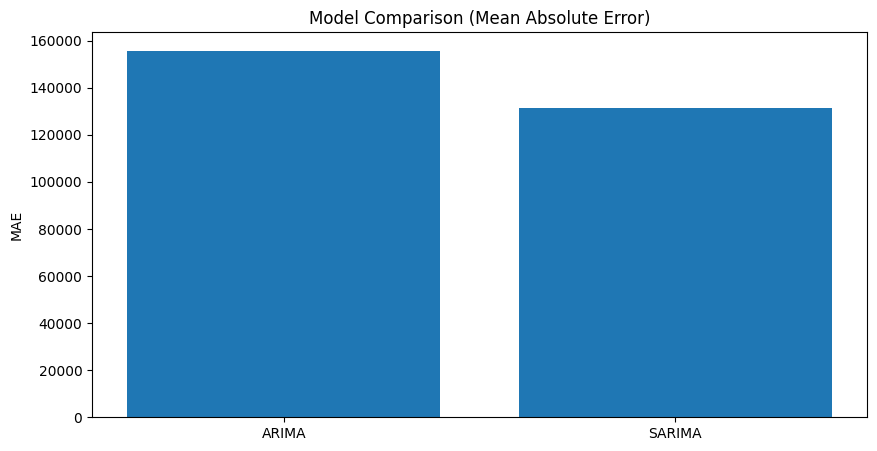

In [21]:
# Plotting The Graph
plt.figure(figsize=(10, 5))
evaluation_metric = ["ARIMA", "SARIMA"]
values = stats_evaluations.loc[0, evaluation_metric]
plt.bar(evaluation_metric, values)
plt.ylabel("MAE")
plt.title("Model Comparison (Mean Absolute Error)")
plt.show()

### CROSS VALIDATION (CV)

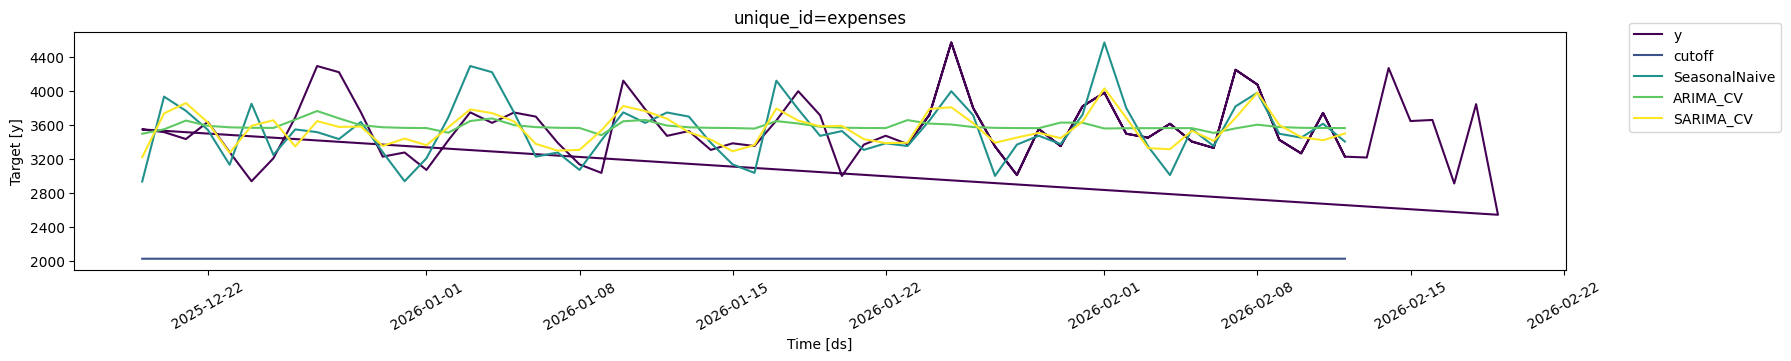

In [22]:
# Now, Without Exogenous Features Cross Validation Of Top Models
models = [
    SeasonalNaive(season_length=7),
    AutoARIMA(seasonal=False, alias="ARIMA_CV"),
    AutoARIMA(season_length=7, alias="SARIMA_CV")
]

cv_forecast = StatsForecast(models=models, freq='D')
cv_predict = cv_forecast.cross_validation(df=train_data_no_exog, h=horizon, step_size=horizon, n_windows=8, refit=True)

# Plotting Time-Series
plot_series(df=daily_transactions, forecasts_df=cv_predict, max_insample_length=28, palette="viridis")

In [23]:
# Evaluting The Performance
cv_evaluation = evaluate(cv_predict.drop(['cutoff'], axis=1), metrics=[mae])
cv_evaluation = cv_evaluation.drop(['unique_id'], axis=1).groupby('metric').mean().reset_index()
cv_evaluation

,metric,SeasonalNaive,ARIMA_CV,SARIMA_CV
0,mae,98587.644346,93352.670453,80958.786911


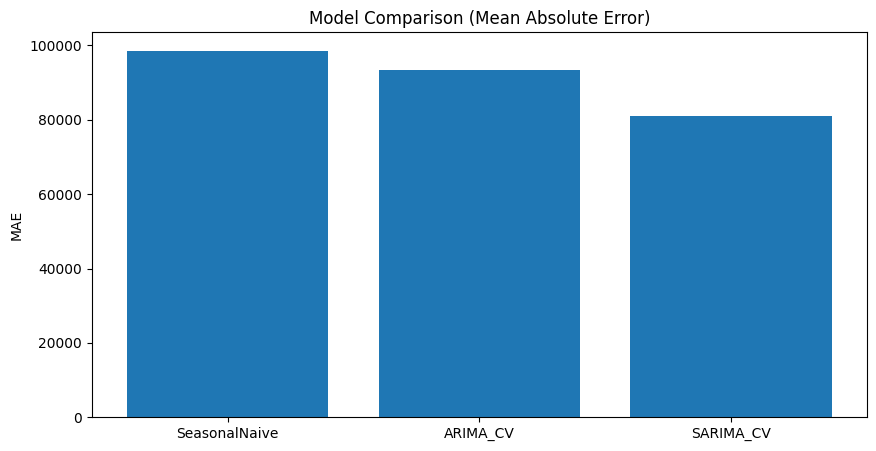

In [24]:
# Plotting The Performance
plt.figure(figsize=(10, 5))
evaluation_metric = ["SeasonalNaive","ARIMA_CV", "SARIMA_CV"]
values = cv_evaluation.loc[0, evaluation_metric]
plt.bar(evaluation_metric, values)
plt.ylabel("MAE")
plt.title("Model Comparison (Mean Absolute Error)")
plt.show()

### EXOGENOUS FEATURES

In [25]:
future_data = test_data.drop(["y"], axis=1)
future_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 725 to 731
Data columns (total 4 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   ds                         7 non-null      datetime64[ns]
 1   category_expenditure_mean  7 non-null      float64       
 2   transactions_count         7 non-null      int64         
 3   unique_id                  7 non-null      object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 356.0+ bytes


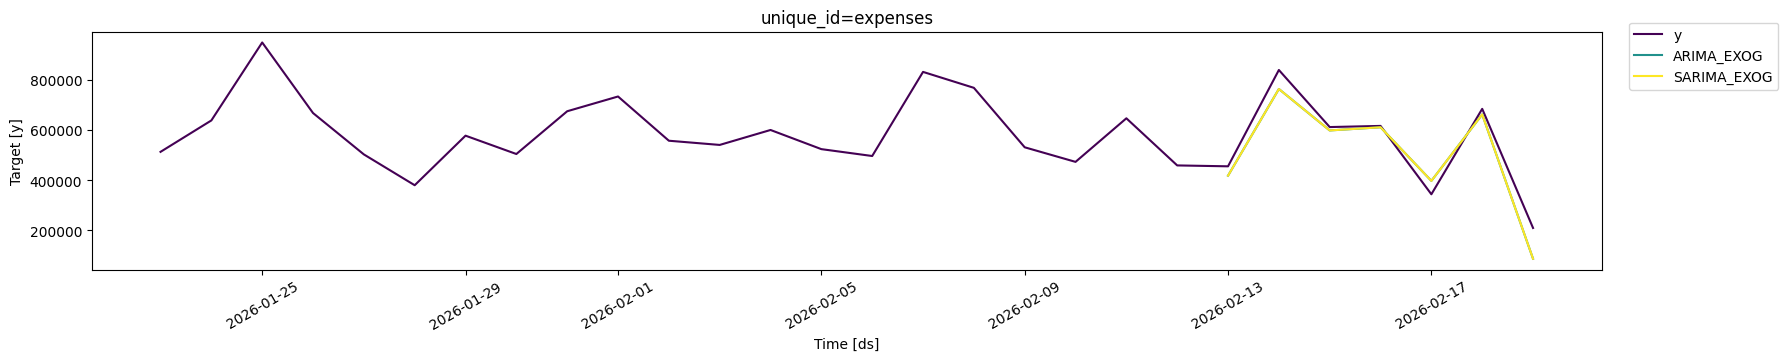

In [26]:
# Defining The Model
models = [
    AutoARIMA(seasonal=False, alias="ARIMA_EXOG"),
    AutoARIMA(season_length=7, alias="SARIMA_EXOG"),
]

# Training The Model
exog_forecast = StatsForecast(models=models, freq="D")
exog_forecast.fit(train_data)
exog_predictions = exog_forecast.predict(h=horizon, X_df=future_data)

#Plotting The Time Series
plot_series(df=daily_transactions, forecasts_df=exog_predictions, max_insample_length=28, palette="viridis")

In [27]:
# Evaluation
exog_evaluate_df = pd.merge(test_data, exog_predictions, on=["unique_id", "ds"])
exog_evaluate = evaluate(
    exog_evaluate_df,
    metrics=[mae]
)
exog_evaluate = exog_evaluate.drop(["unique_id"], axis=1).groupby('metric').mean().reset_index()
exog_evaluate

,metric,category_expenditure_mean,transactions_count,ARIMA_EXOG,SARIMA_EXOG
0,mae,532530.611209,538109.997143,47290.003841,47290.003841


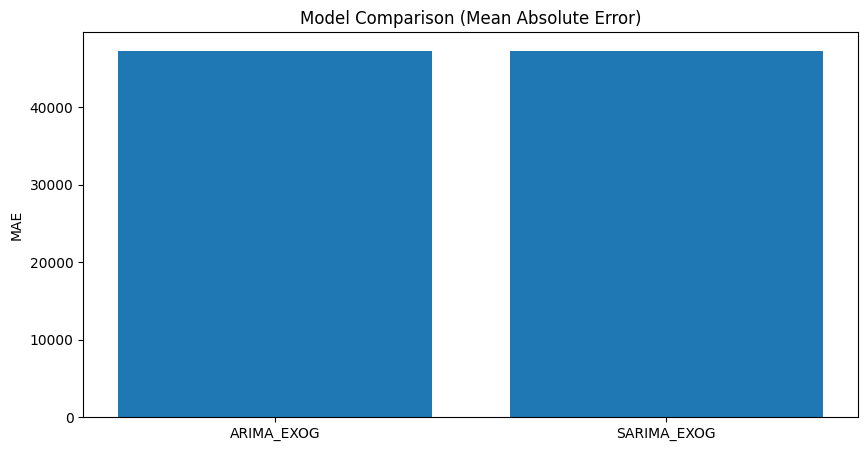

In [28]:
# Plotting The Evaluation
plt.figure(figsize=(10, 5))
evaluation_metric = ["ARIMA_EXOG","SARIMA_EXOG"]
values = exog_evaluate.loc[0, evaluation_metric]
plt.bar(evaluation_metric, values)
plt.ylabel("MAE")
plt.title("Model Comparison (Mean Absolute Error)")
plt.show()

### CV WITH EXOGENOUS

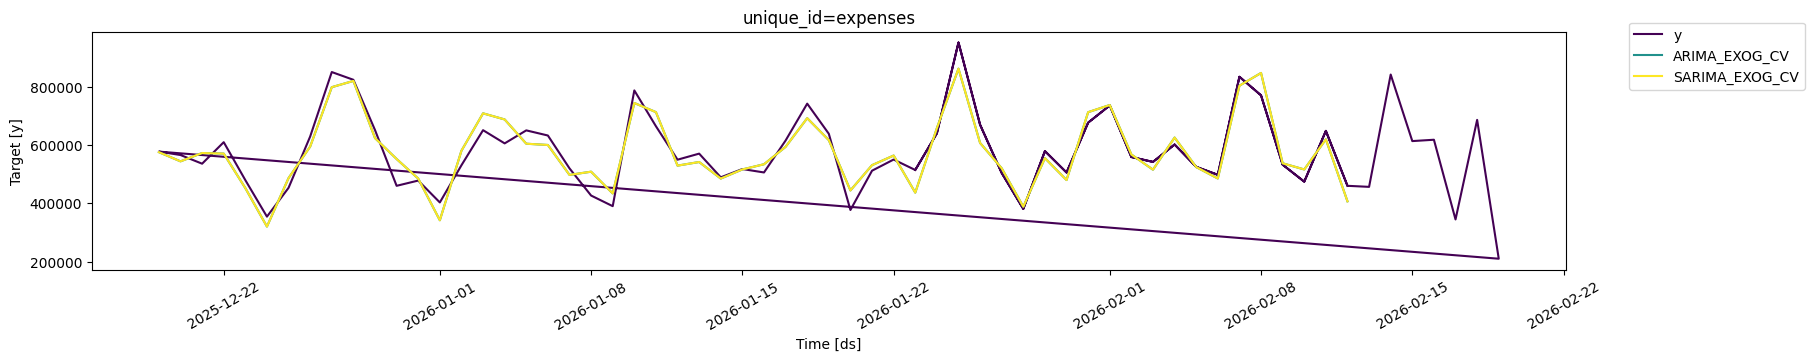

In [29]:
# Defining The Model
models = [
    AutoARIMA(seasonal=False, alias="ARIMA_EXOG_CV"),
    AutoARIMA(season_length=7, alias="SARIMA_EXOG_CV"),
]
# Training The Model
exog_cv_forecast = StatsForecast(models=models, freq="D")
exog_cv_predict = exog_cv_forecast.cross_validation(
    df=train_data,
    h=horizon,
    n_windows=8,
    step_size=horizon,
    refit=True
)
# Plotting The Predictions
plot_series(df=daily_transactions, forecasts_df=exog_cv_predict.drop(["cutoff"], axis=1), max_insample_length=28, palette="viridis")

In [30]:
# Evaluation
exog_cv_evaluate = evaluate(
    exog_cv_predict.drop(['cutoff'], axis=1),
    metrics = [mae]
)
exog_cv_evaluate = exog_cv_evaluate.drop(["unique_id"], axis=1).groupby('metric').mean().reset_index()
exog_cv_evaluate

,metric,ARIMA_EXOG_CV,SARIMA_EXOG_CV
0,mae,34319.477791,34319.477791


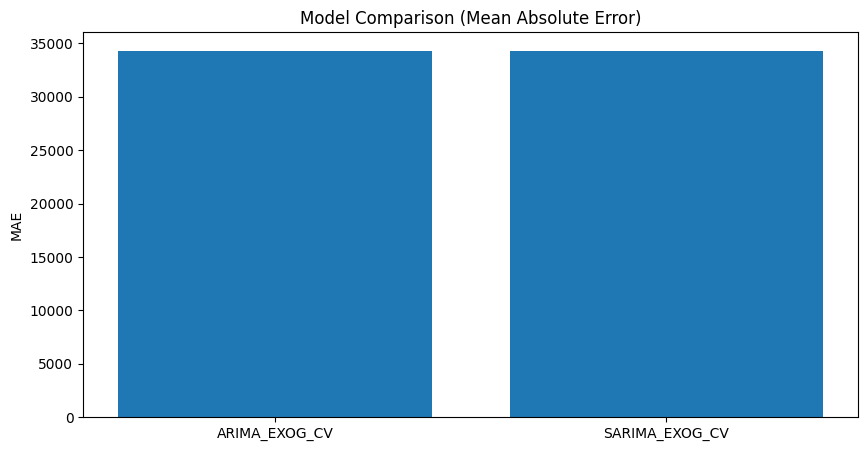

In [31]:
# Plotting The Evaluation
plt.figure(figsize=(10, 5))
evaluation_metric = ["ARIMA_EXOG_CV", "SARIMA_EXOG_CV"]
values = exog_cv_evaluate.loc[0, evaluation_metric]
plt.bar(evaluation_metric, values)
plt.ylabel("MAE")
plt.title("Model Comparison (Mean Absolute Error)")
plt.show()

### CREATING EXOGENOUS FEATURES WITH TIMESTAMPS

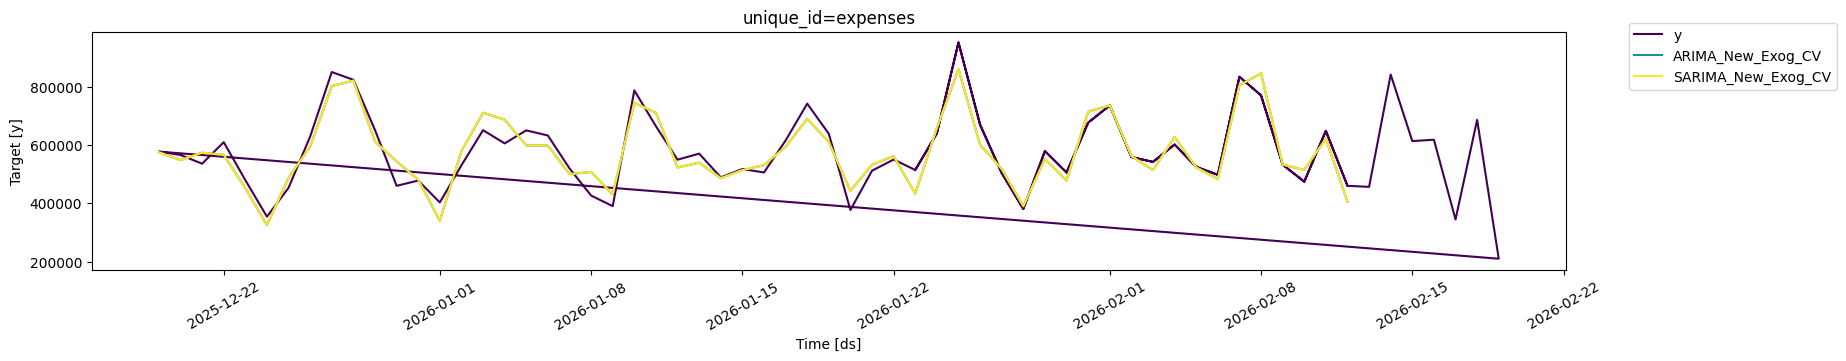

In [32]:
# Creating New Features
features = [
    partial(fourier, season_length=7, k=2),
    partial(time_features, features=["day", "month", "week"])
]
data_new_exog, future_data_new_exog = pipeline(
    df=daily_transactions,
    features=features,
    freq='D',
    h=horizon
)
# Creating New DataSet
test_data_new = data_new_exog.tail(7)
train_data_new = data_new_exog.drop(test_data_new.index)
#Defining Models
models = [
    AutoARIMA(seasonal=False, alias="ARIMA_New_Exog_CV"),
    AutoARIMA(season_length=7, alias="SARIMA_New_Exog_CV")
]
# Training The Model
new_exog_forecast = StatsForecast(models=models, freq='D')
new_exog_predict = new_exog_forecast.cross_validation(
    df= train_data_new,
    h=horizon,
    n_windows=8,
    step_size=horizon,
    refit=True
)
# Plotting Time Series
plot_series(df=data_new_exog, forecasts_df=new_exog_predict.drop(['cutoff'], axis=1), max_insample_length=28, palette="viridis")

In [33]:
# Evaluating The Performance
new_exog_evaluate = evaluate(
    df= new_exog_predict.drop(['cutoff'], axis=1),
    metrics=[mae]
)
new_exog_evaluate = new_exog_evaluate.drop(['unique_id'], axis=1).groupby('metric').mean().reset_index()
new_exog_evaluate

,metric,ARIMA_New_Exog_CV,SARIMA_New_Exog_CV
0,mae,34532.657135,34532.657135


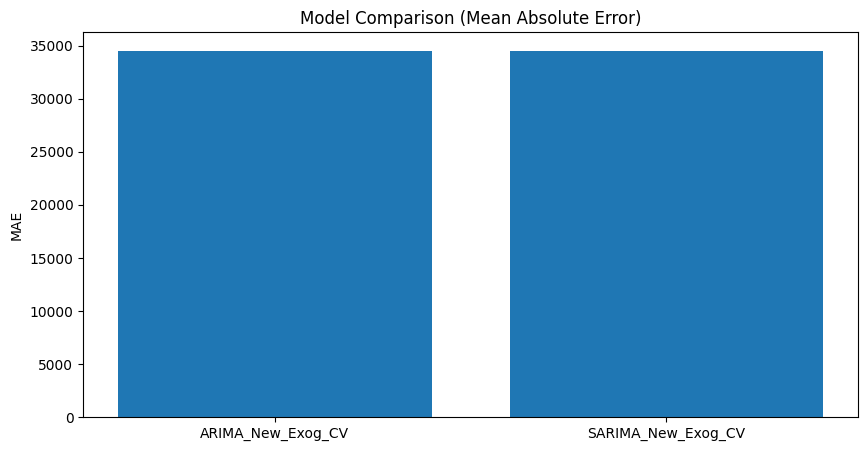

In [34]:
# Plotting The Evaluation
plt.figure(figsize=(10, 5))
evaluation_metric = ["ARIMA_New_Exog_CV", "SARIMA_New_Exog_CV"]
values = new_exog_evaluate.loc[0, evaluation_metric]
plt.bar(evaluation_metric, values)
plt.ylabel("MAE")
plt.title("Model Comparison (Mean Absolute Error)")
plt.show()

### USING PREDICTION INTERVALS

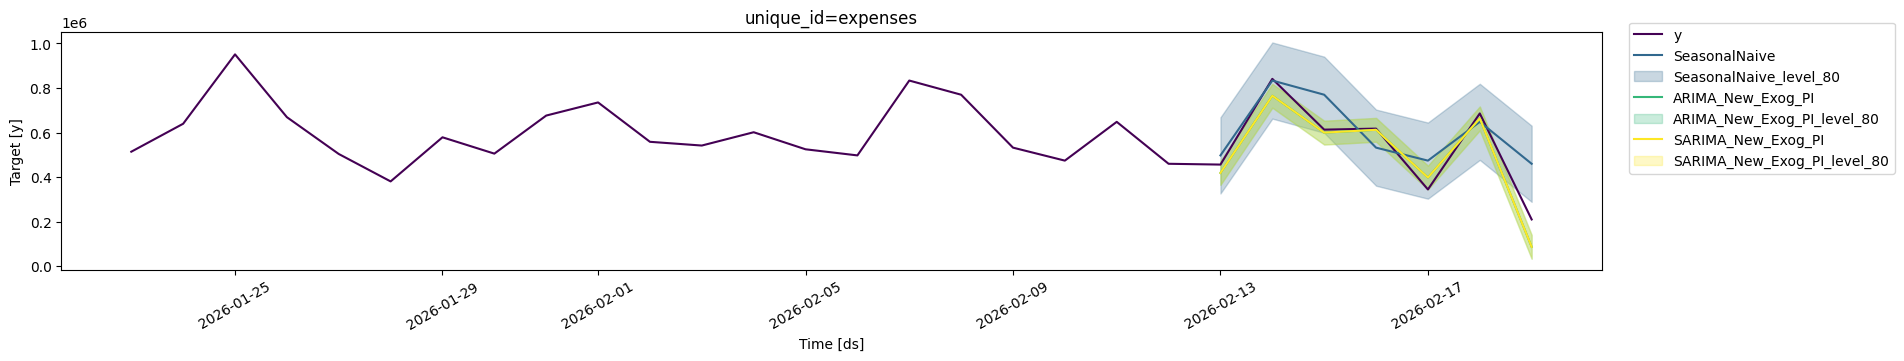

In [35]:
# Defining Models
models = [
    AutoARIMA(seasonal=False, alias="ARIMA_New_Exog_PI"),
    AutoARIMA(season_length=7, alias="SARIMA_New_Exog_PI"),
    SeasonalNaive(season_length=7)
]
# Training Model
new_exog_pi_forecast = StatsForecast(models=models, freq='D')
new_exog_pi_forecast.fit(train_data)
new_exog_pi_predict = new_exog_pi_forecast.predict(
    h=horizon,
    X_df=future_data,
    level=[80]
)
# Plotting Time Series
plot_series(df=daily_transactions, forecasts_df=new_exog_pi_predict, max_insample_length=28, models=["SeasonalNaive", "ARIMA_New_Exog_PI", "SARIMA_New_Exog_PI"], level=[80], palette="viridis")

In [36]:
# Evaluation Of The Model's Performance
new_exog_pi_df = pd.merge(test_data, new_exog_pi_predict, on=["unique_id", "ds"])
new_exog_pi_evaluate = evaluate(df=new_exog_pi_df, metrics=[mae])
new_exog_pi_evaluate = new_exog_pi_evaluate.drop(["unique_id"], axis=1).groupby("metric").mean().reset_index()
new_exog_pi_evaluate

,metric,category_expenditure_mean,transactions_count,ARIMA_New_Exog_PI,SARIMA_New_Exog_PI,SeasonalNaive
0,mae,532530.611209,538109.997143,47290.003841,47290.003841,101200.281429


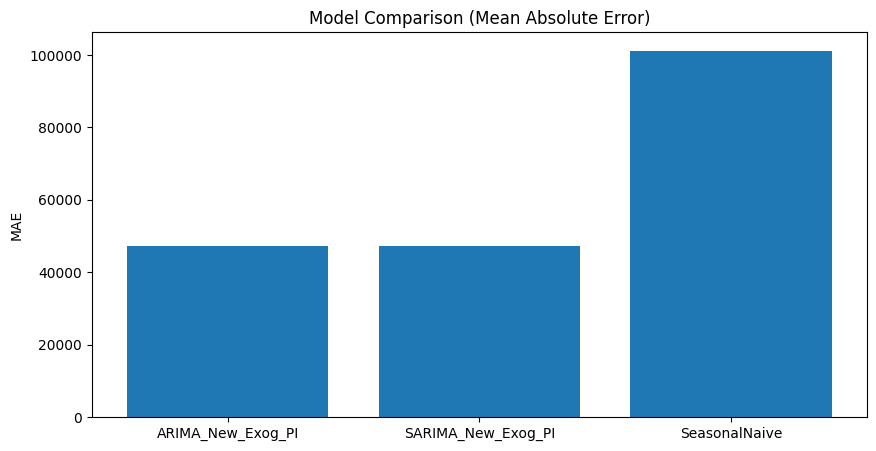

In [37]:
# Plotting The Performance
plt.figure(figsize=(10, 5))
evaluation_metric = ["ARIMA_New_Exog_PI", "SARIMA_New_Exog_PI", "SeasonalNaive"]
values = new_exog_pi_evaluate.loc[0, evaluation_metric]
plt.bar(evaluation_metric, values)
plt.ylabel("MAE")
plt.title("Model Comparison (Mean Absolute Error)")
plt.show()

### PREDICTION INTERVALS WITH CV

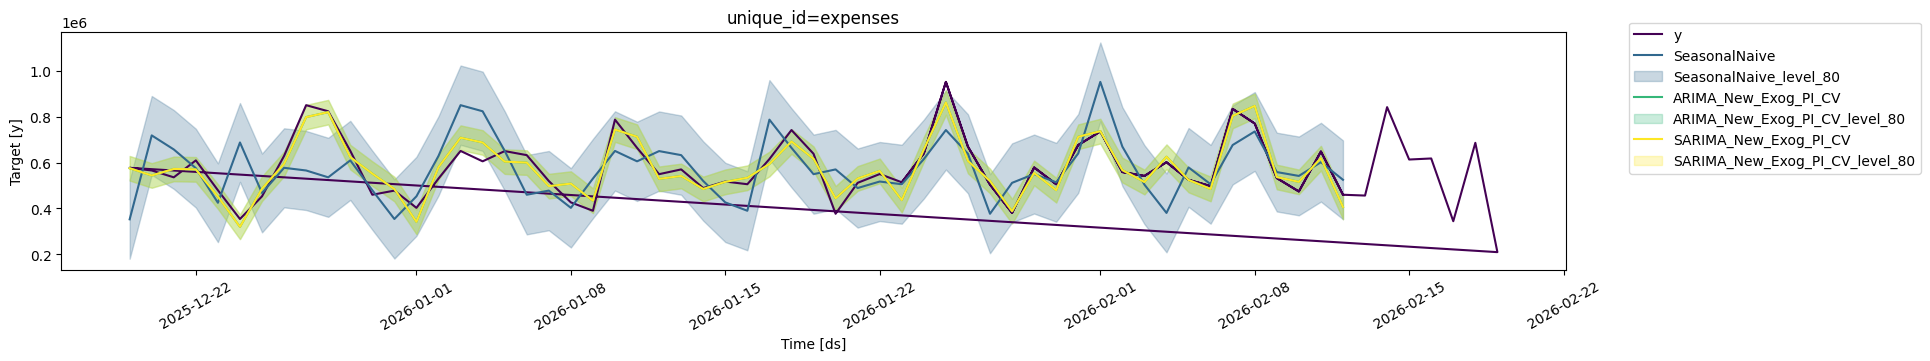

In [38]:
# Defining Models
models = [
    AutoARIMA(seasonal=False, alias="ARIMA_New_Exog_PI_CV"),
    AutoARIMA(season_length=7, alias="SARIMA_New_Exog_PI_CV"),
    SeasonalNaive(season_length=7)
]
# Training Model
new_exog_pi_cv_forecast = StatsForecast(models=models, freq='D')
new_exog_pi_cv_predict = new_exog_pi_cv_forecast.cross_validation(
    df=train_data,
    h=horizon,
    level=[80],
    n_windows=8,
    step_size=horizon,
    refit=True
)
# Plotting Time Series
plot_series(df=daily_transactions, forecasts_df=new_exog_pi_cv_predict, max_insample_length=28, models=["SeasonalNaive", "ARIMA_New_Exog_PI_CV", "SARIMA_New_Exog_PI_CV"], level=[80], palette="viridis")

In [39]:
# Evaluations
new_exog_pi_cv_evaluate = evaluate(new_exog_pi_cv_predict.drop(["cutoff"], axis=1), metrics=[mae])
new_exog_pi_cv_evaluate = new_exog_pi_cv_evaluate.drop(["unique_id"], axis=1).groupby("metric").mean().reset_index()
new_exog_pi_cv_evaluate

,metric,ARIMA_New_Exog_PI_CV,SARIMA_New_Exog_PI_CV,SeasonalNaive
0,mae,34319.477791,34319.477791,98587.644346


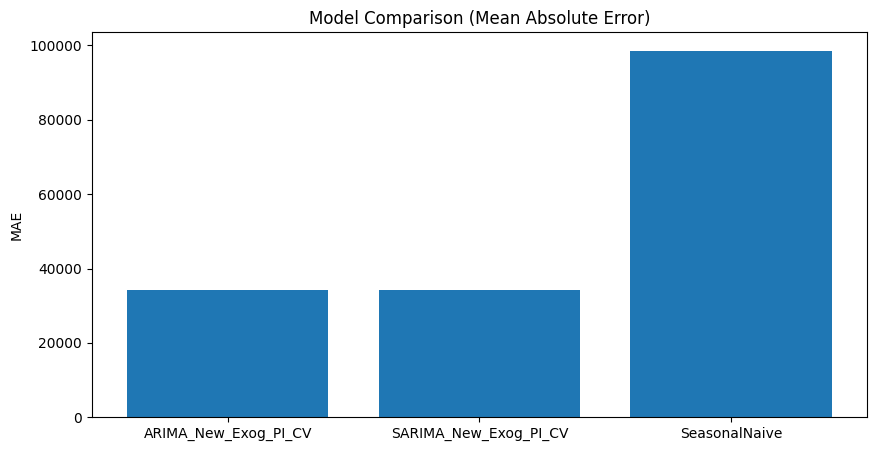

In [40]:
# Plotting The Performance
plt.figure(figsize=(10, 5))
evaluation_metric = ["ARIMA_New_Exog_PI_CV", "SARIMA_New_Exog_PI_CV", "SeasonalNaive"]
values = new_exog_pi_cv_evaluate.loc[0, evaluation_metric]
plt.bar(evaluation_metric, values)
plt.ylabel("MAE")
plt.title("Model Comparison (Mean Absolute Error)")
plt.show()

### EVALUATION METRICS [TOP - 3]

In [41]:
models = [
    AutoARIMA(season_length=7, alias="SARIMA_New_Exog_PI_CV"),
    AutoARIMA(seasonal=False, alias="ARIMA_New_Exog_PI_CV"),
    SeasonalNaive(season_length=7)
]

final_forecast = StatsForecast(models=models, freq="D")
final_predictions = final_forecast.cross_validation(
    df=daily_transactions,
    h=horizon,
    n_windows=8,
    step_size=horizon,
    refit=True,
    level=[80]
)

In [42]:
models = ["SARIMA_New_Exog_PI_CV", "ARIMA_New_Exog_PI_CV", "SeasonalNaive"]
metrics = [
    mae,
    mse,
    rmse,
    mape,
    smape
]

final_eval = evaluate(
    final_predictions.drop(["ds", "cutoff"], axis=1),
    metrics=metrics,
    models=models,
    level=[80]
)

final_eval.head(10)

,unique_id,metric,SARIMA_New_Exog_PI_CV,ARIMA_New_Exog_PI_CV,SeasonalNaive
0,expenses,mae,3.676292e+04,3.676292e+04,9.454631e+04
1,expenses,mse,2.092150e+09,2.092150e+09,1.466048e+10
2,expenses,rmse,4.574003e+04,4.574003e+04,1.210805e+05
3,expenses,mape,7.220786e-02,7.220786e-02,1.765067e-01
4,expenses,smape,3.802093e-02,3.802093e-02,8.381331e-02
